In [3]:
import sys, subprocess, importlib, platform, os

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def pip_install(*args):
    print("pip install", " ".join(args))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

try:
    import pytorch_fid
    _fid_version = getattr(pytorch_fid, "__version__", None)
except ImportError:
    _fid_version = None

if _fid_version != "0.3.0":
    if "pytorch_fid" in sys.modules:
        raise RuntimeError(
            f"pytorch-fid {_fid_version} is already imported. Install 0.3.0, restart the runtime and re-run."
        )
    pip_install("--no-deps", "pytorch-fid==0.3.0")
    importlib.invalidate_caches()
    import pytorch_fid
assert pytorch_fid.__version__ == "0.3.0", pytorch_fid.__version__

try:
    import skimage
except ImportError:
    pip_install("scikit-image")
    importlib.invalidate_caches()
    import skimage

import copy, csv, hashlib, io, json, math, random, time
from pathlib import Path

import numpy as np
import scipy
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import ConcatDataset, DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else (platform.processor() or platform.machine())

ENV_INFO = {
    "in_colab": IN_COLAB,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "scikit_image": skimage.__version__,
    "matplotlib": matplotlib.__version__,
    "pytorch_fid": pytorch_fid.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "device": str(DEVICE),
    "hardware": HARDWARE,
}
print(json.dumps(ENV_INFO, indent=2))
if DEVICE.type != "cuda":
    print("WARNING: no GPU detected. Select Runtime > Change runtime type > GPU in Colab.")

{
  "in_colab": true,
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "scipy": "1.16.3",
  "scikit_image": "0.25.2",
  "matplotlib": "3.10.0",
  "pytorch_fid": "0.3.0",
  "cuda_available": true,
  "cuda_version": "13.0",
  "cudnn_version": 92800,
  "device": "cuda",
  "hardware": "Tesla T4"
}


In [4]:
SEED = 42


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/generative-model-comparison/04_vae")
else:
    PROJECT_ROOT = Path("./generative-model-comparison/04_vae").resolve()
    print("Not running in Colab; using local fallback root:", PROJECT_ROOT)

DATA_DIR = PROJECT_ROOT / "data" / "fashion_mnist"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
CKPT_DIR = RESULTS_DIR / "checkpoints"
for d in (DATA_DIR, RESULTS_DIR, FIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = RESULTS_DIR / "best_model.pth"
LAST_CKPT_PATH = CKPT_DIR / "last_checkpoint.pth"
METRICS_PATH = RESULTS_DIR / "metrics.json"
HISTORY_CSV_PATH = RESULTS_DIR / "training_history.csv"
CONFIG_PATH = RESULTS_DIR / "experiment_config.json"
SPLIT_REPORT_PATH = RESULTS_DIR / "split_report.json"
FIG_TRAINING_CURVES = FIG_DIR / "training_curves.png"
FIG_RANDOM_SAMPLES = FIG_DIR / "random_samples_4x4.png"
FIG_RECONSTRUCTION = FIG_DIR / "reconstruction_comparison.png"
FIG_INTERPOLATION = FIG_DIR / "latent_interpolation.png"

RESUME_FROM_LAST = False

NUM_CLASSES = 10
N_OFFICIAL_TRAIN, N_OFFICIAL_TEST, N_POOLED = 60_000, 10_000, 70_000
N_TRAIN_PER_CLASS, N_VAL_PER_CLASS, N_TEST_PER_CLASS = 5_600, 700, 700
N_TRAIN, N_VAL, N_TEST = 56_000, 7_000, 7_000
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

BATCH_SIZE = 128
NUM_WORKERS = 2
PIN_MEMORY = DEVICE.type == "cuda"

INPUT_DIM, HIDDEN_DIM, LATENT_DIM = 784, 256, 64
LOGVAR_MIN, LOGVAR_MAX = -20.0, 10.0
EXPECTED_TRAINABLE_PARAMS = 451_984

BETA = 1.0
KL_WARMUP_EPOCHS = 0
KL_ANNEALING = None
LEARNING_RATE = 1e-3
ADAM_BETAS = (0.9, 0.999)
ADAM_EPS = 1e-8
WEIGHT_DECAY = 0.0
NUM_EPOCHS = 30
VAL_EPS_SEED = SEED + 6000

FID_DIMS = 2048
FID_BATCH_SIZE = 64
VAL_FID_EVERY = 5
VAL_FID_EPOCHS = list(range(VAL_FID_EVERY, NUM_EPOCHS + 1, VAL_FID_EVERY))
VAL_FID_N = 3_000
VAL_FID_LATENT_SEED = SEED + 7000
TEST_FID_N = 7_000
TEST_FID_LATENT_SEED = SEED + 8000

SSIM_KWARGS = dict(data_range=1.0, gaussian_weights=True, sigma=1.5,
                   win_size=11, use_sample_covariance=False)

SAMPLES_SEED = SEED + 9000
N_RANDOM_SAMPLES = 16
RECON_CLASSES = list(range(8))
INTERP_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
INTERP_CLASS_A, INTERP_CLASS_B = 0, 1

LATENCY_BATCH = 64
LATENCY_WARMUP = 20
LATENCY_RUNS = 100

CONFIG = {
    "model_name": "04_vae",
    "seed": SEED,
    "dataset": {
        "name": "Fashion-MNIST",
        "pooling": "official train (60000) then official test (10000)",
        "n_pooled": N_POOLED,
        "transform": "ToTensor() only; grayscale [1,28,28] in [0,1]",
        "split_rng": "np.random.default_rng(42)",
        "per_class": {"train": N_TRAIN_PER_CLASS, "val": N_VAL_PER_CLASS, "test": N_TEST_PER_CLASS},
        "totals": {"train": N_TRAIN, "val": N_VAL, "test": N_TEST},
    },
    "dataloader": {
        "batch_size": BATCH_SIZE, "train_shuffle": True, "val_shuffle": False, "test_shuffle": False,
        "train_generator": "dedicated CPU torch.Generator seeded 42",
        "num_workers": NUM_WORKERS, "pin_memory": PIN_MEMORY,
    },
    "architecture": {
        "type": "fully connected VAE",
        "encoder": ["Flatten(784)", "Linear(784,256)", "ReLU", "mu: Linear(256,64)", "logvar: Linear(256,64)"],
        "decoder": ["Linear(64,256)", "ReLU", "Linear(256,784)", "Sigmoid", "Reshape[B,1,28,28]"],
        "input_dim": INPUT_DIM, "hidden_dim": HIDDEN_DIM, "latent_dim": LATENT_DIM,
        "logvar_clamp": [LOGVAR_MIN, LOGVAR_MAX],
        "reparameterization": "std = exp(0.5*logvar); z = mu + std*eps, eps ~ N(0,I)",
        "deterministic_reconstruction": "decode(mu)",
        "expected_trainable_params": EXPECTED_TRAINABLE_PARAMS,
    },
    "objective": {
        "reconstruction": "sum of squared pixel error over 784 pixels per image, mean over batch",
        "kl": "-0.5*sum(1 + logvar - mu^2 - exp(logvar)) over 64 dims per image, mean over batch",
        "total": "reconstruction_sse + beta * kl",
        "beta": BETA, "kl_warmup_epochs": KL_WARMUP_EPOCHS, "kl_annealing": KL_ANNEALING,
    },
    "optimizer": {
        "name": "Adam", "lr": LEARNING_RATE, "betas": list(ADAM_BETAS), "eps": ADAM_EPS,
        "weight_decay": WEIGHT_DECAY,
    },
    "training": {
        "epochs": NUM_EPOCHS, "scheduler": None, "early_stopping": False, "gradient_clipping": None,
        "mixed_precision": False, "extra_regularization": None,
        "train_eps": "random (global torch RNG)",
        "val_eps_seed": VAL_EPS_SEED,
        "val_eps_generator": "dedicated CPU torch.Generator reset at every validation epoch",
        "checkpoint_selection": "lowest validation total objective",
    },
    "fid": {
        "package": "pytorch-fid==0.3.0 (installed with --no-deps)",
        "inception": "FID InceptionV3 weights, pool3", "feature_dim": FID_DIMS,
        "preprocessing": "grayscale repeated to RGB, [0,1] input, wrapper bilinear resize to 299x299 + normalisation",
        "statistics_dtype": "float64",
        "feature_batch_size": FID_BATCH_SIZE,
        "val_every_epochs": VAL_FID_EVERY, "val_epochs": VAL_FID_EPOCHS,
        "val_n_real": VAL_FID_N, "val_n_generated": VAL_FID_N,
        "val_real_images": "first 3000 images of the validation split",
        "val_latent_seed": VAL_FID_LATENT_SEED,
        "val_fid_role": "diagnostic only; not used for checkpoint selection",
        "test_n_real": TEST_FID_N, "test_n_generated": TEST_FID_N,
        "test_latent_seed": TEST_FID_LATENT_SEED,
    },
    "reconstruction_metrics": {
        "images": "all 7000 test images, posterior-mean reconstructions decode(mu)",
        "mse": "global total squared error / all test pixels, float64",
        "psnr": "10*log10(1.0/MSE)",
        "ssim": SSIM_KWARGS,
    },
    "figures": {
        "random_samples": N_RANDOM_SAMPLES, "random_samples_seed": SAMPLES_SEED,
        "reconstruction_classes": RECON_CLASSES,
        "interpolation_classes": [INTERP_CLASS_A, INTERP_CLASS_B],
        "interpolation_alphas": INTERP_ALPHAS,
        "sample_selection": "first image of each class in shuffled test split order",
    },
    "latency": {
        "definition": "prior sampling + decoder forward pass (no encoder, no FID)",
        "batch_size": LATENCY_BATCH, "warmup_runs": LATENCY_WARMUP, "timed_runs": LATENCY_RUNS,
        "no_grad": True, "cuda_synchronize": True,
    },
}

def to_jsonable(obj):
    """Convert to strict-JSON-compatible types; NaN -> None, +/-inf -> "inf"/"-inf"."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    if isinstance(obj, torch.Tensor):
        return to_jsonable(obj.detach().cpu().tolist())
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        v = float(obj)
        if math.isnan(v):
            return None
        if math.isinf(v):
            return "inf" if v > 0 else "-inf"
        return v
    if isinstance(obj, Path):
        return str(obj)
    return obj


def atomic_write_text(path, text):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        f.write(text)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def atomic_write_json(path, obj):
    atomic_write_text(path, json.dumps(to_jsonable(obj), indent=2, allow_nan=False))


def atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def save_figure(fig, path, dpi=150):
    path = Path(path)
    tmp = path.with_name(path.stem + ".tmp" + path.suffix)
    fig.savefig(tmp, dpi=dpi, bbox_inches="tight")
    os.replace(tmp, path)


def sha256_int64(arr):
    return hashlib.sha256(np.ascontiguousarray(arr, dtype=np.int64).tobytes()).hexdigest()


def strict_json_load(path):
    def _reject(token):
        raise ValueError(f"Non-strict JSON constant {token!r} in {path}")
    with open(path, "r", encoding="utf-8") as f:
        return json.loads(f.read(), parse_constant=_reject)


atomic_write_json(CONFIG_PATH, CONFIG)
print("Project root:", PROJECT_ROOT)
print("Config saved to", CONFIG_PATH)

Mounted at /content/drive
Project root: /content/drive/MyDrive/generative-model-comparison/04_vae
Config saved to /content/drive/MyDrive/generative-model-comparison/04_vae/results/experiment_config.json


In [5]:
transform = transforms.ToTensor()
official_train = datasets.FashionMNIST(root=str(DATA_DIR), train=True, download=True, transform=transform)
official_test = datasets.FashionMNIST(root=str(DATA_DIR), train=False, download=True, transform=transform)
assert len(official_train) == N_OFFICIAL_TRAIN and len(official_test) == N_OFFICIAL_TEST

pooled_dataset = ConcatDataset([official_train, official_test])
assert len(pooled_dataset) == N_POOLED

pooled_labels = np.concatenate([
    np.asarray(official_train.targets.numpy(), dtype=np.int64),
    np.asarray(official_test.targets.numpy(), dtype=np.int64),
]).astype(np.int64)


def make_stratified_split(labels, seed=SEED):
    """Exact split algorithm shared with Models 01-03."""
    rng = np.random.default_rng(seed)
    train_parts, val_parts, test_parts = [], [], []
    for class_id in range(NUM_CLASSES):
        idx = np.flatnonzero(labels == class_id).copy()
        rng.shuffle(idx)
        train_parts.append(idx[:N_TRAIN_PER_CLASS])
        val_parts.append(idx[N_TRAIN_PER_CLASS:N_TRAIN_PER_CLASS + N_VAL_PER_CLASS])
        test_parts.append(idx[N_TRAIN_PER_CLASS + N_VAL_PER_CLASS:])
    train = np.concatenate(train_parts).astype(np.int64)
    val = np.concatenate(val_parts).astype(np.int64)
    test = np.concatenate(test_parts).astype(np.int64)
    rng.shuffle(train)
    rng.shuffle(val)
    rng.shuffle(test)
    return train, val, test


def verify_split(train, val, test, labels):
    per_class = {
        name: np.bincount(labels[arr], minlength=NUM_CLASSES).tolist()
        for name, arr in (("train", train), ("val", val), ("test", test))
    }
    union = np.concatenate([train, val, test])
    checks = {
        "dtype_int64": all(a.dtype == np.int64 for a in (train, val, test)),
        "train_total_56000": len(train) == N_TRAIN,
        "val_total_7000": len(val) == N_VAL,
        "test_total_7000": len(test) == N_TEST,
        "train_per_class_5600": all(c == N_TRAIN_PER_CLASS for c in per_class["train"]),
        "val_per_class_700": all(c == N_VAL_PER_CLASS for c in per_class["val"]),
        "test_per_class_700": all(c == N_TEST_PER_CLASS for c in per_class["test"]),
        "no_duplicates_train": len(np.unique(train)) == len(train),
        "no_duplicates_val": len(np.unique(val)) == len(val),
        "no_duplicates_test": len(np.unique(test)) == len(test),
        "disjoint_train_val": len(np.intersect1d(train, val)) == 0,
        "disjoint_train_test": len(np.intersect1d(train, test)) == 0,
        "disjoint_val_test": len(np.intersect1d(val, test)) == 0,
        "full_coverage_70000": np.array_equal(np.sort(union), np.arange(N_POOLED, dtype=np.int64)),
    }
    return checks, per_class


train_idx, val_idx, test_idx = make_stratified_split(pooled_labels, SEED)
split_checks, split_per_class = verify_split(train_idx, val_idx, test_idx, pooled_labels)
for k, v in split_checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(split_checks.values()), "Split verification failed"

_t2, _v2, _s2 = make_stratified_split(pooled_labels, SEED)
assert np.array_equal(_t2, train_idx) and np.array_equal(_v2, val_idx) and np.array_equal(_s2, test_idx)

SPLIT_HASHES = {
    "train_sha256": sha256_int64(train_idx),
    "val_sha256": sha256_int64(val_idx),
    "test_sha256": sha256_int64(test_idx),
    "pooled_labels_sha256": sha256_int64(pooled_labels),
}
MODEL01_SPLIT_REPORT_PATH = (
    "/content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/split_report.json"
)
assert os.path.isfile(MODEL01_SPLIT_REPORT_PATH), (
    "Run Model 01 completely first; its split_report.json is the canonical split reference."
)
with open(MODEL01_SPLIT_REPORT_PATH) as f:
    model01_hashes = json.load(f)["index_sha256_int64"]

local_hashes = {
    "train": SPLIT_HASHES["train_sha256"],
    "validation": SPLIT_HASHES["val_sha256"],
    "test": SPLIT_HASHES["test_sha256"],
}
assert local_hashes == model01_hashes, (
    f"Model 04 split differs from Model 01. Local={local_hashes}; Model01={model01_hashes}"
)
print("PASS: Model 04 split hashes exactly match Model 01.")
split_report = {
    "seed": SEED,
    "rng": "np.random.default_rng(42)",
    "pooling_order": ["official_train (60000)", "official_test (10000)"],
    "algorithm": [
        "concatenate train and test targets as int64",
        "rng = np.random.default_rng(42)",
        "for class_id in 0..9: idx = np.flatnonzero(labels == class_id).copy(); rng.shuffle(idx); "
        "first 5600 -> train, next 700 -> val, remaining 700 -> test",
        "concatenate each split as int64",
        "rng.shuffle(train); rng.shuffle(val); rng.shuffle(test)",
    ],
    "totals": {"train": len(train_idx), "val": len(val_idx), "test": len(test_idx)},
    "per_class_counts": split_per_class,
    "checks": split_checks,
    "hash_method": "sha256 of np.ascontiguousarray(indices, dtype=np.int64).tobytes()",
    "hashes": SPLIT_HASHES,
    "first_10_indices": {"train": train_idx[:10], "val": val_idx[:10], "test": test_idx[:10]},
}
atomic_write_json(SPLIT_REPORT_PATH, split_report)
print(json.dumps(to_jsonable(SPLIT_HASHES), indent=2))

100%|██████████| 26.4M/26.4M [00:00<00:00, 120MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 7.63MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 58.9MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 30.0MB/s]


PASS  dtype_int64
PASS  train_total_56000
PASS  val_total_7000
PASS  test_total_7000
PASS  train_per_class_5600
PASS  val_per_class_700
PASS  test_per_class_700
PASS  no_duplicates_train
PASS  no_duplicates_val
PASS  no_duplicates_test
PASS  disjoint_train_val
PASS  disjoint_train_test
PASS  disjoint_val_test
PASS  full_coverage_70000
PASS: Model 04 split hashes exactly match Model 01.
{
  "train_sha256": "33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f",
  "val_sha256": "ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254",
  "test_sha256": "e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1",
  "pooled_labels_sha256": "138bc5cbc39ee06b83e673e3675e93334169ceae7849de38016fa7ef57c6ffba"
}


train=56000  val=7000  test=7000
batches/epoch: train=438  val=55  test=55


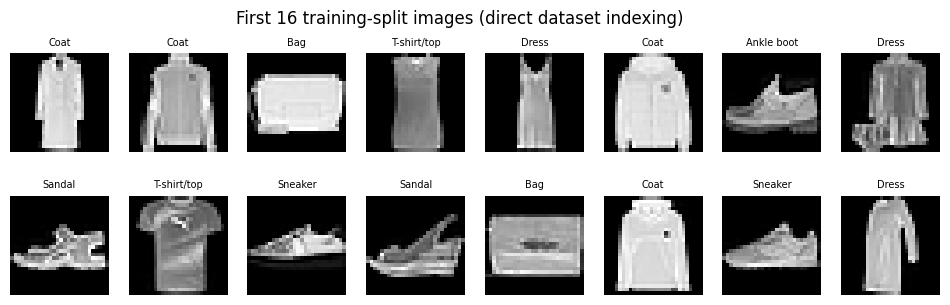

val batch: (128, 1, 28, 28) torch.float32 range=[0.000, 1.000]


In [6]:
train_set = Subset(pooled_dataset, train_idx.tolist())
val_set = Subset(pooled_dataset, val_idx.tolist())
test_set = Subset(pooled_dataset, test_idx.tolist())

train_generator = torch.Generator(device="cpu")
train_generator.manual_seed(SEED)
INITIAL_TRAIN_GENERATOR_STATE = train_generator.get_state().clone()

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")
print(f"batches/epoch: train={len(train_loader)}  val={len(val_loader)}  test={len(test_loader)}")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.flat):
    img, lab = train_set[i]
    assert img.shape == (1, 28, 28) and img.dtype == torch.float32
    assert 0.0 <= img.min().item() and img.max().item() <= 1.0
    assert lab == pooled_labels[train_idx[i]]
    ax.imshow(img[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[lab], fontsize=7)
    ax.axis("off")
fig.suptitle("First 16 training-split images (direct dataset indexing)")
plt.show()

xb, yb = next(iter(val_loader))
print("val batch:", tuple(xb.shape), xb.dtype, f"range=[{xb.min():.3f}, {xb.max():.3f}]")
assert xb.shape == (BATCH_SIZE, 1, 28, 28)
assert torch.equal(yb, torch.as_tensor(pooled_labels[val_idx[:BATCH_SIZE]]))
assert torch.equal(train_generator.get_state(), INITIAL_TRAIN_GENERATOR_STATE)

In [7]:
def clamp_logvar(logvar):
    return torch.clamp(logvar, LOGVAR_MIN, LOGVAR_MAX)


class VAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(input_dim, hidden_dim), nn.ReLU())
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, input_dim), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = clamp_logvar(self.fc_logvar(h))
        return mu, logvar

    def reparameterize(self, mu, logvar, eps=None):
        std = torch.exp(0.5 * logvar)
        if eps is None:
            eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x, eps=None):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar, eps)
        return self.decode(z), mu, logvar, z


def count_trainable_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def architecture_signature(m):
    return [type(mod).__name__ for mod in m.modules() if not isinstance(mod, (VAE, nn.Sequential))]


EXPECTED_SIGNATURE = ["Flatten", "Linear", "ReLU", "Linear", "Linear", "Linear", "ReLU", "Linear", "Sigmoid"]

torch.manual_seed(SEED)
model = VAE().to(DEVICE)
n_params = count_trainable_params(model)
print(model)
print("Trainable parameters:", f"{n_params:,}")
assert n_params == EXPECTED_TRAINABLE_PARAMS, n_params
assert architecture_signature(model) == EXPECTED_SIGNATURE, architecture_signature(model)
assert not any(isinstance(mod, (nn.Conv1d, nn.Conv2d, nn.ConvTranspose2d, nn.Dropout,
                                nn.BatchNorm1d, nn.BatchNorm2d)) for mod in model.modules())
assert (model.fc_mu.in_features, model.fc_mu.out_features) == (256, 64)
assert (model.fc_logvar.in_features, model.fc_logvar.out_features) == (256, 64)

with torch.no_grad():
    x_chk = torch.stack([val_set[i][0] for i in range(8)]).to(DEVICE)
    x_hat, mu, logvar, z = model(x_chk, eps=torch.zeros(8, LATENT_DIM, device=DEVICE))
    assert x_hat.shape == (8, 1, 28, 28) and mu.shape == logvar.shape == z.shape == (8, 64)
    assert torch.allclose(z, mu)  # eps = 0 -> z = mu
    assert torch.allclose(model.decode(mu), x_hat)
    assert x_hat.min() >= 0 and x_hat.max() <= 1
    assert logvar.min() >= LOGVAR_MIN and logvar.max() <= LOGVAR_MAX
assert torch.equal(clamp_logvar(torch.tensor([-100.0, 0.0, 100.0])), torch.tensor([-20.0, 0.0, 10.0]))
print("Architecture assertions passed.")

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Trainable parameters: 451,984
Architecture assertions passed.


In [8]:
def vae_loss(x_hat, x, mu, logvar, beta=BETA):
    recon_per_image = (x_hat - x).pow(2).flatten(1).sum(dim=1)
    kl_per_image = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)
    recon = recon_per_image.mean()
    kl = kl_per_image.mean()
    total = recon + beta * kl
    return total, recon, kl, recon_per_image, kl_per_image


_x = torch.rand(4, 1, 28, 28, generator=torch.Generator().manual_seed(0))
_zeros = torch.zeros(4, LATENT_DIM)

t, r, k, _, _ = vae_loss(_x, _x, _zeros, _zeros)
assert abs(t.item()) < 1e-6 and abs(r.item()) < 1e-6 and abs(k.item()) < 1e-6

_, r, _, rp, _ = vae_loss(_x + 0.1, _x, _zeros, _zeros)
assert abs(r.item() - 7.84) < 1e-3 and rp.shape == (4,)

_, _, k, _, kp = vae_loss(_x, _x, torch.ones(4, LATENT_DIM), _zeros)
assert abs(k.item() - 32.0) < 1e-4 and kp.shape == (4,)

t, r, k, _, _ = vae_loss(_x + 0.1, _x, torch.ones(4, LATENT_DIM), _zeros)
assert abs(t.item() - (r.item() + BETA * k.item())) < 1e-4
assert BETA == 1.0 and KL_WARMUP_EPOCHS == 0 and KL_ANNEALING is None
print("Loss checks passed. beta =", BETA, "| warm-up epochs =", KL_WARMUP_EPOCHS)

Loss checks passed. beta = 1.0 | warm-up epochs = 0


In [9]:
FID_BLOCK_IDX = InceptionV3.BLOCK_INDEX_BY_DIM[FID_DIMS]
inception = InceptionV3([FID_BLOCK_IDX], resize_input=True, normalize_input=True,
                        use_fid_inception=True).to(DEVICE).eval()


@torch.no_grad()
def inception_features_batch(x01):
    x = x01.to(DEVICE, dtype=torch.float32)
    assert x.dim() == 4 and x.shape[1] == 1
    x = x.repeat(1, 3, 1, 1)
    feat = inception(x)[0]
    if feat.shape[2] != 1 or feat.shape[3] != 1:
        feat = F.adaptive_avg_pool2d(feat, output_size=(1, 1))
    return feat.squeeze(3).squeeze(2).double().cpu()


def features_from_loader(loader):
    feats = [inception_features_batch(x) for x, _ in loader]
    return torch.cat(feats).numpy().astype(np.float64)


def features_from_images(images, batch_size=FID_BATCH_SIZE):
    feats = [inception_features_batch(images[i:i + batch_size]) for i in range(0, images.size(0), batch_size)]
    return torch.cat(feats).numpy().astype(np.float64)


@torch.no_grad()
def generate_from_latents(m, z, batch_size=FID_BATCH_SIZE):
    m.eval()
    out = [m.decode(z[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, z.size(0), batch_size)]
    return torch.cat(out)


def feature_statistics(feats):
    feats = np.asarray(feats, dtype=np.float64)
    assert feats.ndim == 2 and feats.shape[1] == FID_DIMS
    return feats.mean(axis=0), np.cov(feats, rowvar=False)


def fid_from_stats(mu1, s1, mu2, s2):
    value = float(calculate_frechet_distance(mu1, s1, mu2, s2))
    if not math.isfinite(value):
        raise FloatingPointError(f"Non-finite FID value: {value}")
    if value < 0.0:
        if value < -1e-6:
            raise ValueError(f"Materially negative FID value: {value}")
        value = 0.0
    return value


val_fid_real_set = Subset(pooled_dataset, val_idx[:VAL_FID_N].tolist())
val_fid_real_loader = DataLoader(val_fid_real_set, batch_size=FID_BATCH_SIZE, shuffle=False,
                                 num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
t0 = time.perf_counter()
VAL_REAL_FEATS = features_from_loader(val_fid_real_loader)
assert VAL_REAL_FEATS.shape == (VAL_FID_N, FID_DIMS) and VAL_REAL_FEATS.dtype == np.float64
VAL_REAL_MU, VAL_REAL_SIGMA = feature_statistics(VAL_REAL_FEATS)
print(f"Validation real features {VAL_REAL_FEATS.shape} in {time.perf_counter() - t0:.1f}s")

VAL_FID_Z = torch.randn(VAL_FID_N, LATENT_DIM, generator=torch.Generator().manual_seed(VAL_FID_LATENT_SEED))
print("Fixed validation-FID latent tensor:", tuple(VAL_FID_Z.shape))

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 203MB/s]


Validation real features (3000, 2048) in 11.9s
Fixed validation-FID latent tensor: (3000, 64)


In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=ADAM_BETAS,
                             eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)

HISTORY_FIELDS = [
    "epoch", "beta",
    "train_total", "train_recon_sse", "train_kl",
    "val_total", "val_recon_sse", "val_kl",
    "val_fid",
    "train_time_s", "val_time_s", "val_fid_time_s", "epoch_wall_time_s",
    "is_best",
]


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def write_history_csv(history, path):
    buf = io.StringIO()
    writer = csv.DictWriter(buf, fieldnames=HISTORY_FIELDS, lineterminator="\n")
    writer.writeheader()
    for row in history:
        writer.writerow({k: ("" if row.get(k) is None else row.get(k)) for k in HISTORY_FIELDS})
    atomic_write_text(path, buf.getvalue())


def capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "train_loader_generator": train_generator.get_state(),
    }


def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch_cpu"])
    if state["torch_cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["torch_cuda"])
    train_generator.set_state(state["train_loader_generator"])


def train_one_epoch(m, loader):
    m.train()
    s_total = s_recon = s_kl = 0.0
    n = 0
    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=PIN_MEMORY)
        optimizer.zero_grad(set_to_none=True)
        x_hat, mu, logvar, _ = m(x)
        total, recon, kl, _, _ = vae_loss(x_hat, x, mu, logvar, beta=BETA)
        total.backward()
        optimizer.step()
        b = x.size(0)
        s_total += total.item() * b
        s_recon += recon.item() * b
        s_kl += kl.item() * b
        n += b
    return {"total": s_total / n, "recon_sse": s_recon / n, "kl": s_kl / n}


@torch.no_grad()
def evaluate_objective(m, loader, eps_seed=VAL_EPS_SEED):
    """Deterministic objective: the CPU generator is reset so every epoch uses the same eps."""
    m.eval()
    g = torch.Generator(device="cpu")
    g.manual_seed(eps_seed)
    s_total = s_recon = s_kl = 0.0
    n = 0
    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=PIN_MEMORY)
        mu, logvar = m.encode(x)
        eps = torch.randn(mu.shape, generator=g).to(DEVICE)
        x_hat = m.decode(m.reparameterize(mu, logvar, eps))
        total, recon, kl, _, _ = vae_loss(x_hat, x, mu, logvar, beta=BETA)
        b = x.size(0)
        s_total += total.item() * b
        s_recon += recon.item() * b
        s_kl += kl.item() * b
        n += b
    return {"total": s_total / n, "recon_sse": s_recon / n, "kl": s_kl / n}


def compute_val_fid(m):
    fake = generate_from_latents(m, VAL_FID_Z)
    assert fake.shape == (VAL_FID_N, 1, 28, 28)
    feats = features_from_images(fake)
    mu_g, s_g = feature_statistics(feats)
    return fid_from_stats(VAL_REAL_MU, VAL_REAL_SIGMA, mu_g, s_g)


history = []
best_val_total = float("inf")
best_epoch = None
start_epoch = 1

if RESUME_FROM_LAST:
    if LAST_CKPT_PATH.exists():
        ckpt = torch.load(LAST_CKPT_PATH, map_location="cpu", weights_only=False)
        assert to_jsonable(ckpt["config"]) == to_jsonable(CONFIG), "Checkpoint config differs from current CONFIG"
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        history = ckpt["history"]
        best_val_total = ckpt["best_val_total"]
        best_epoch = ckpt["best_epoch"]
        start_epoch = ckpt["completed_epoch"] + 1
        restore_rng_state(ckpt["rng_state"])
        assert BEST_MODEL_PATH.exists(), "Resuming requires the existing best_model.pth"
        print(f"Resumed after epoch {ckpt['completed_epoch']} (best epoch {best_epoch}, val total {best_val_total:.4f})")
    else:
        print("RESUME_FROM_LAST=True but no last checkpoint found; starting from scratch.")

if start_epoch == 1:
    assert torch.equal(train_generator.get_state(), INITIAL_TRAIN_GENERATOR_STATE)

for epoch in range(start_epoch, NUM_EPOCHS + 1):
    t_epoch = time.perf_counter()

    t0 = time.perf_counter()
    tr = train_one_epoch(model, train_loader)
    sync()
    train_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    va = evaluate_objective(model, val_loader, VAL_EPS_SEED)
    sync()
    val_time = time.perf_counter() - t0

    val_fid, val_fid_time = None, 0.0
    if epoch % VAL_FID_EVERY == 0:
        t0 = time.perf_counter()
        val_fid = compute_val_fid(model)
        sync()
        val_fid_time = time.perf_counter() - t0

    is_best = va["total"] < best_val_total
    if is_best:
        best_val_total, best_epoch = va["total"], epoch
        atomic_torch_save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_total": va["total"], "val_recon_sse": va["recon_sse"], "val_kl": va["kl"],
            "selection_metric": "val_total",
            "trainable_params": count_trainable_params(model),
            "config": CONFIG,
        }, BEST_MODEL_PATH)

    epoch_wall = time.perf_counter() - t_epoch
    row = {
        "epoch": epoch, "beta": BETA,
        "train_total": tr["total"], "train_recon_sse": tr["recon_sse"], "train_kl": tr["kl"],
        "val_total": va["total"], "val_recon_sse": va["recon_sse"], "val_kl": va["kl"],
        "val_fid": val_fid,
        "train_time_s": train_time, "val_time_s": val_time, "val_fid_time_s": val_fid_time,
        "epoch_wall_time_s": epoch_wall,
        "is_best": bool(is_best),
    }
    history.append(row)
    write_history_csv(history, HISTORY_CSV_PATH)

    atomic_torch_save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "completed_epoch": epoch,
        "best_val_total": best_val_total,
        "best_epoch": best_epoch,
        "selection_metric": "val_total",
        "history": history,
        "rng_state": capture_rng_state(),
        "config": CONFIG,
    }, LAST_CKPT_PATH)

    fid_str = f"{val_fid:.2f}" if val_fid is not None else "-"
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
          f"train {tr['total']:.3f} (SSE {tr['recon_sse']:.3f}, KL {tr['kl']:.3f}) | "
          f"val {va['total']:.3f} (SSE {va['recon_sse']:.3f}, KL {va['kl']:.3f}) | "
          f"valFID {fid_str} | t {train_time:.1f}/{val_time:.1f}/{val_fid_time:.1f}s wall {epoch_wall:.1f}s"
          f"{' | BEST' if is_best else ''}")

assert len(history) == NUM_EPOCHS and [h["epoch"] for h in history] == list(range(1, NUM_EPOCHS + 1))
print(f"Training finished. Best epoch {best_epoch} with validation total objective {best_val_total:.4f}")

Epoch 01/30 | train 45.618 (SSE 39.204, KL 6.414) | val 36.247 (SSE 27.960, KL 8.288) | valFID - | t 9.3/0.9/0.0s wall 10.2s | BEST
Epoch 02/30 | train 33.924 (SSE 26.015, KL 7.910) | val 31.717 (SSE 24.201, KL 7.516) | valFID - | t 7.0/1.7/0.0s wall 8.8s | BEST
Epoch 03/30 | train 30.431 (SSE 22.926, KL 7.505) | val 29.042 (SSE 21.559, KL 7.483) | valFID - | t 8.3/0.9/0.0s wall 9.2s | BEST
Epoch 04/30 | train 28.443 (SSE 21.027, KL 7.416) | val 27.605 (SSE 20.116, KL 7.488) | valFID - | t 8.6/0.9/0.0s wall 9.6s | BEST
Epoch 05/30 | train 27.413 (SSE 19.876, KL 7.537) | val 26.839 (SSE 19.371, KL 7.467) | valFID 130.85 | t 7.2/0.9/29.6s wall 37.7s | BEST
Epoch 06/30 | train 26.771 (SSE 19.130, KL 7.640) | val 26.390 (SSE 18.742, KL 7.647) | valFID - | t 8.8/0.9/0.0s wall 9.7s | BEST
Epoch 07/30 | train 26.394 (SSE 18.664, KL 7.730) | val 26.019 (SSE 18.243, KL 7.776) | valFID - | t 7.6/1.3/0.0s wall 8.9s | BEST
Epoch 08/30 | train 26.120 (SSE 18.337, KL 7.783) | val 25.782 (SSE 17.998,

Loaded best checkpoint: epoch 30, val total 24.2920


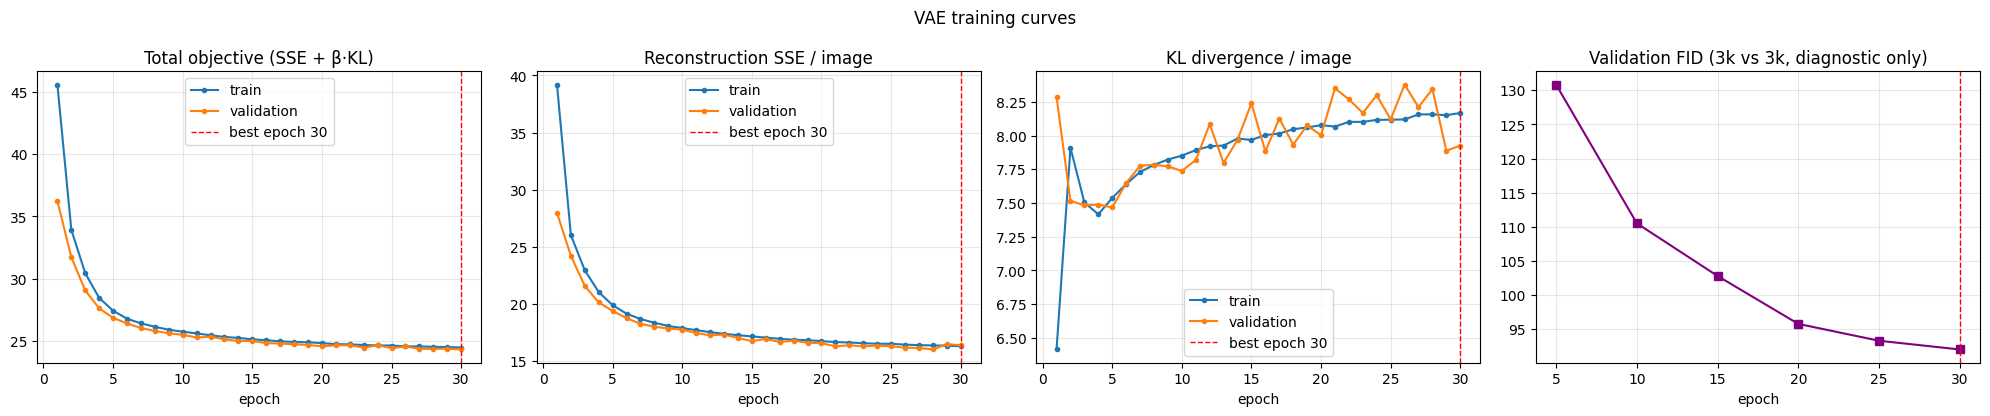

In [11]:
best_ckpt = torch.load(BEST_MODEL_PATH, map_location="cpu", weights_only=False)
best_model = VAE().to(DEVICE)
best_model.load_state_dict(best_ckpt["model_state_dict"])
best_model.eval()
for p in best_model.parameters():
    p.requires_grad_(False)

epochs = [h["epoch"] for h in history]
val_totals = [h["val_total"] for h in history]
argmin_epoch = epochs[int(np.argmin(val_totals))]
assert best_ckpt["epoch"] == best_epoch == argmin_epoch, (best_ckpt["epoch"], best_epoch, argmin_epoch)
print(f"Loaded best checkpoint: epoch {best_ckpt['epoch']}, val total {best_ckpt['val_total']:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
panels = [("total", "Total objective (SSE + β·KL)"), ("recon_sse", "Reconstruction SSE / image"),
          ("kl", "KL divergence / image")]
for ax, (key, title) in zip(axes[:3], panels):
    ax.plot(epochs, [h[f"train_{key}"] for h in history], marker="o", ms=3, label="train")
    ax.plot(epochs, [h[f"val_{key}"] for h in history], marker="o", ms=3, label="validation")
    ax.axvline(best_epoch, color="red", ls="--", lw=1, label=f"best epoch {best_epoch}")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
fid_points = [(h["epoch"], h["val_fid"]) for h in history if h["val_fid"] is not None]
axes[3].plot([e for e, _ in fid_points], [f for _, f in fid_points], marker="s", color="purple")
axes[3].axvline(best_epoch, color="red", ls="--", lw=1)
axes[3].set_title("Validation FID (3k vs 3k, diagnostic only)"); axes[3].set_xlabel("epoch"); axes[3].grid(alpha=0.3)
fig.suptitle("VAE training curves")
fig.tight_layout()
save_figure(fig, FIG_TRAINING_CURVES)
plt.show()

In [12]:
@torch.no_grad()
def evaluate_reconstruction(m, loader):
    m.eval()
    total_se, n_pixels, kl_sum, n_images = 0.0, 0, 0.0, 0
    ssim_values = []
    for x, _ in loader:
        x = x.to(DEVICE)
        mu, logvar = m.encode(x)
        x_hat = m.decode(mu)
        x64, r64 = x.double(), x_hat.double()
        total_se += (r64 - x64).pow(2).sum().item()
        n_pixels += x.numel()
        kl = -0.5 * (1 + logvar.double() - mu.double().pow(2) - logvar.double().exp()).sum(dim=1)
        kl_sum += kl.sum().item()
        n_images += x.size(0)
        x_np, r_np = x64.cpu().numpy(), r64.cpu().numpy()
        for i in range(x_np.shape[0]):
            ssim_values.append(structural_similarity(x_np[i, 0], r_np[i, 0], **SSIM_KWARGS))
    mse = total_se / n_pixels
    psnr = 10.0 * math.log10(1.0 / mse) if mse > 0 else float("inf")
    ssim_arr = np.asarray(ssim_values, dtype=np.float64)
    return {
        "n_images": n_images, "n_pixels": n_pixels,
        "total_squared_error": total_se,
        "mse": mse, "psnr_db": psnr,
        "ssim_mean": float(ssim_arr.mean()), "ssim_std": float(ssim_arr.std()),
        "ssim_count": int(ssim_arr.size), "ssim_settings": SSIM_KWARGS,
        "mean_kl_diagnostic": kl_sum / n_images,
        "reconstruction": "decode(mu) (posterior mean)",
        "checkpoint_epoch": best_ckpt["epoch"],
    }


t0 = time.perf_counter()
test_recon_metrics = evaluate_reconstruction(best_model, test_loader)
test_recon_metrics["eval_time_s"] = time.perf_counter() - t0
assert test_recon_metrics["n_images"] == N_TEST and test_recon_metrics["ssim_count"] == N_TEST
assert test_recon_metrics["n_pixels"] == N_TEST * 784
print(json.dumps(to_jsonable(test_recon_metrics), indent=2))

{
  "n_images": 7000,
  "n_pixels": 5488000,
  "total_squared_error": 93977.23886688646,
  "mse": 0.0171241324465901,
  "psnr_db": 17.663914217743798,
  "ssim_mean": 0.5824995837333303,
  "ssim_std": 0.19669770702204423,
  "ssim_count": 7000,
  "ssim_settings": {
    "data_range": 1.0,
    "gaussian_weights": true,
    "sigma": 1.5,
    "win_size": 11,
    "use_sample_covariance": false
  },
  "mean_kl_diagnostic": 7.933291106911077,
  "reconstruction": "decode(mu) (posterior mean)",
  "checkpoint_epoch": 30,
  "eval_time_s": 6.325760461999835
}


In [13]:
t0 = time.perf_counter()
TEST_REAL_FEATS = features_from_loader(test_loader)
test_fid_z = torch.randn(TEST_FID_N, LATENT_DIM, generator=torch.Generator().manual_seed(TEST_FID_LATENT_SEED))
test_fake_images = generate_from_latents(best_model, test_fid_z)
TEST_FAKE_FEATS = features_from_images(test_fake_images)
assert TEST_REAL_FEATS.shape == (TEST_FID_N, FID_DIMS) and TEST_FAKE_FEATS.shape == (TEST_FID_N, FID_DIMS)
assert TEST_REAL_FEATS.dtype == np.float64 and TEST_FAKE_FEATS.dtype == np.float64

mu_r, s_r = feature_statistics(TEST_REAL_FEATS)
mu_g, s_g = feature_statistics(TEST_FAKE_FEATS)
test_fid_value = fid_from_stats(mu_r, s_r, mu_g, s_g)
test_fid_metrics = {
    "fid": test_fid_value,
    "n_real": int(TEST_REAL_FEATS.shape[0]),
    "n_generated": int(TEST_FAKE_FEATS.shape[0]),
    "feature_dim": int(TEST_REAL_FEATS.shape[1]),
    "real_source": "held-out test split (7000 images); no training images",
    "generated_source": "z ~ N(0, I), decoded by best checkpoint",
    "latent_seed": TEST_FID_LATENT_SEED,
    "inception": "pytorch-fid 0.3.0 FID InceptionV3, pool3",
    "statistics_dtype": "float64",
    "checkpoint_epoch": best_ckpt["epoch"],
    "time_s": time.perf_counter() - t0,
    "limitations": "ImageNet-trained Inception on upsampled grayscale 28x28 images; compare only within this protocol.",
}
print(json.dumps(to_jsonable(test_fid_metrics), indent=2))

{
  "fid": 89.46050485739553,
  "n_real": 7000,
  "n_generated": 7000,
  "feature_dim": 2048,
  "real_source": "held-out test split (7000 images); no training images",
  "generated_source": "z ~ N(0, I), decoded by best checkpoint",
  "latent_seed": 8042,
  "inception": "pytorch-fid 0.3.0 FID InceptionV3, pool3",
  "statistics_dtype": "float64",
  "checkpoint_epoch": 30,
  "time_s": 68.85532322900008,
  "limitations": "ImageNet-trained Inception on upsampled grayscale 28x28 images; compare only within this protocol."
}


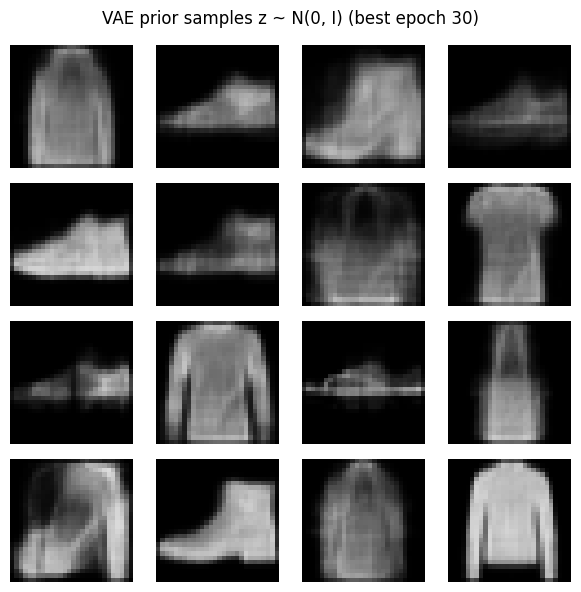

In [14]:
samples_z = torch.randn(N_RANDOM_SAMPLES, LATENT_DIM, generator=torch.Generator().manual_seed(SAMPLES_SEED))
samples = generate_from_latents(best_model, samples_z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle(f"VAE prior samples z ~ N(0, I) (best epoch {best_ckpt['epoch']})")
fig.tight_layout()
save_figure(fig, FIG_RANDOM_SAMPLES)
plt.show()
random_samples_info = {"n_samples": N_RANDOM_SAMPLES, "latent_seed": SAMPLES_SEED, "grid": "4x4"}

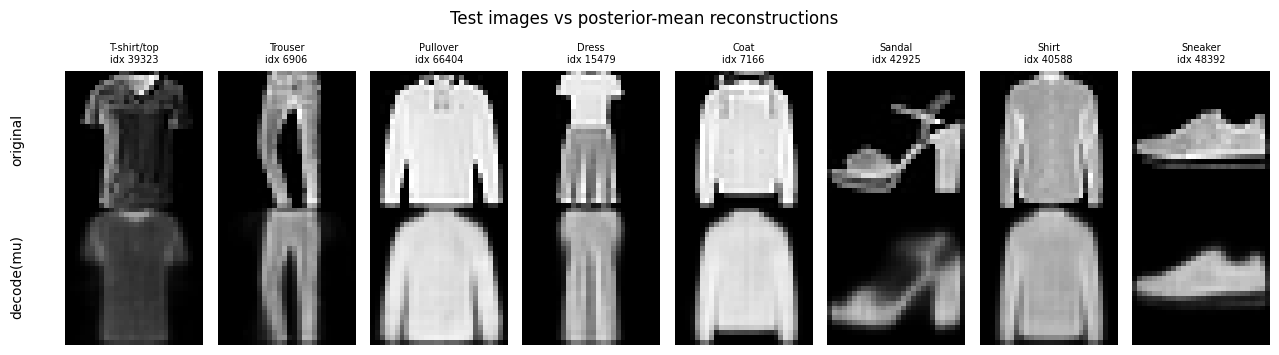

[
  {
    "test_split_position": 0,
    "pooled_index": 39323,
    "class_id": 0,
    "class_name": "T-shirt/top",
    "official_source": "train",
    "official_source_index": 39323
  },
  {
    "test_split_position": 3,
    "pooled_index": 6906,
    "class_id": 1,
    "class_name": "Trouser",
    "official_source": "train",
    "official_source_index": 6906
  },
  {
    "test_split_position": 17,
    "pooled_index": 66404,
    "class_id": 2,
    "class_name": "Pullover",
    "official_source": "test",
    "official_source_index": 6404
  },
  {
    "test_split_position": 5,
    "pooled_index": 15479,
    "class_id": 3,
    "class_name": "Dress",
    "official_source": "train",
    "official_source_index": 15479
  },
  {
    "test_split_position": 12,
    "pooled_index": 7166,
    "class_id": 4,
    "class_name": "Coat",
    "official_source": "train",
    "official_source_index": 7166
  },
  {
    "test_split_position": 1,
    "pooled_index": 42925,
    "class_id": 5,
    "class_name":

In [15]:
def describe_pooled_index(split_pos, pooled_index):
    pooled_index = int(pooled_index)
    cls = int(pooled_labels[pooled_index])
    return {
        "test_split_position": int(split_pos),
        "pooled_index": pooled_index,
        "class_id": cls,
        "class_name": CLASS_NAMES[cls],
        "official_source": "train" if pooled_index < N_OFFICIAL_TRAIN else "test",
        "official_source_index": pooled_index if pooled_index < N_OFFICIAL_TRAIN else pooled_index - N_OFFICIAL_TRAIN,
    }


def first_test_position_of_class(class_id):
    return int(np.flatnonzero(pooled_labels[test_idx] == class_id)[0])


recon_samples = [describe_pooled_index(p, test_idx[p])
                 for p in (first_test_position_of_class(c) for c in RECON_CLASSES)]
x_rec = torch.stack([test_set[s["test_split_position"]][0] for s in recon_samples])
with torch.no_grad():
    mu_rec, _ = best_model.encode(x_rec.to(DEVICE))
    r_rec = best_model.decode(mu_rec).cpu()

n = len(recon_samples)
fig, axes = plt.subplots(2, n, figsize=(1.6 * n, 3.6))
for j, s in enumerate(recon_samples):
    axes[0, j].imshow(x_rec[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"{s['class_name']}\nidx {s['pooled_index']}", fontsize=7)
    axes[1, j].imshow(r_rec[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].text(-0.3, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.3, 0.5, "decode(mu)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
fig.suptitle("Test images vs posterior-mean reconstructions")
fig.tight_layout()
save_figure(fig, FIG_RECONSTRUCTION)
plt.show()
print(json.dumps(recon_samples, indent=2))

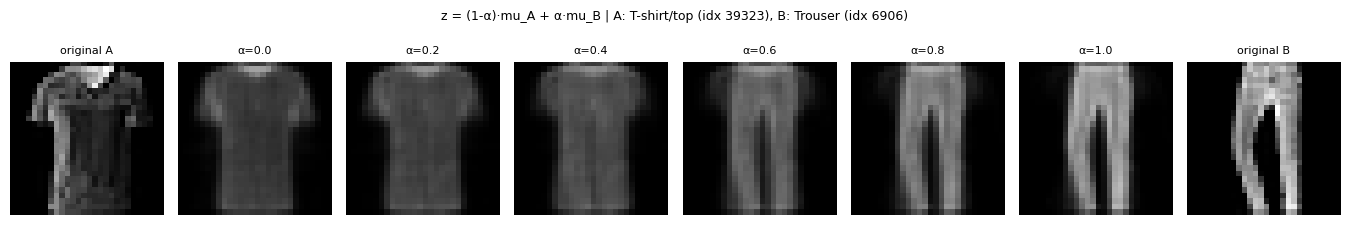

{
  "endpoint_a": {
    "test_split_position": 0,
    "pooled_index": 39323,
    "class_id": 0,
    "class_name": "T-shirt/top",
    "official_source": "train",
    "official_source_index": 39323
  },
  "endpoint_b": {
    "test_split_position": 3,
    "pooled_index": 6906,
    "class_id": 1,
    "class_name": "Trouser",
    "official_source": "train",
    "official_source_index": 6906
  },
  "alphas": [
    0.0,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0
  ],
  "latent": "posterior means; z = (1 - alpha) * mu_A + alpha * mu_B"
}


In [16]:
_pos_a = first_test_position_of_class(INTERP_CLASS_A)
_pos_b = first_test_position_of_class(INTERP_CLASS_B)
interp_a = describe_pooled_index(_pos_a, test_idx[_pos_a])
interp_b = describe_pooled_index(_pos_b, test_idx[_pos_b])
assert interp_a["class_id"] == 0 and interp_b["class_id"] == 1
x_a = test_set[_pos_a][0].unsqueeze(0)
x_b = test_set[_pos_b][0].unsqueeze(0)

with torch.no_grad():
    mu_a, _ = best_model.encode(x_a.to(DEVICE))
    mu_b, _ = best_model.encode(x_b.to(DEVICE))
    z_interp = torch.cat([(1.0 - a) * mu_a + a * mu_b for a in INTERP_ALPHAS])
    interp_imgs = best_model.decode(z_interp).cpu()

fig, axes = plt.subplots(1, len(INTERP_ALPHAS) + 2, figsize=(1.7 * (len(INTERP_ALPHAS) + 2), 2.4))
axes[0].imshow(x_a[0, 0].numpy(), cmap="gray", vmin=0, vmax=1); axes[0].set_title("original A", fontsize=8)
for j, a in enumerate(INTERP_ALPHAS):
    axes[j + 1].imshow(interp_imgs[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[j + 1].set_title(f"α={a:.1f}", fontsize=8)
axes[-1].imshow(x_b[0, 0].numpy(), cmap="gray", vmin=0, vmax=1); axes[-1].set_title("original B", fontsize=8)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"z = (1-α)·mu_A + α·mu_B | A: {interp_a['class_name']} (idx {interp_a['pooled_index']}), "
             f"B: {interp_b['class_name']} (idx {interp_b['pooled_index']})", fontsize=9)
fig.tight_layout()
save_figure(fig, FIG_INTERPOLATION)
plt.show()

interpolation_info = {"endpoint_a": interp_a, "endpoint_b": interp_b, "alphas": INTERP_ALPHAS,
                      "latent": "posterior means; z = (1 - alpha) * mu_A + alpha * mu_B"}
print(json.dumps(interpolation_info, indent=2))

In [17]:
@torch.no_grad()
def generate_batch(m, batch_size):
    z = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
    return m.decode(z)


best_model.eval()
with torch.no_grad():
    for _ in range(LATENCY_WARMUP):
        generate_batch(best_model, LATENCY_BATCH)
    sync()
    latency_ms = []
    for _ in range(LATENCY_RUNS):
        sync()
        t0 = time.perf_counter()
        out = generate_batch(best_model, LATENCY_BATCH)
        sync()
        latency_ms.append((time.perf_counter() - t0) * 1000.0)
assert out.shape == (LATENCY_BATCH, 1, 28, 28) and len(latency_ms) == LATENCY_RUNS

lat = np.asarray(latency_ms, dtype=np.float64)
latency_metrics = {
    "definition": "prior sampling + decoder forward pass; encoder and FID excluded",
    "batch_size": LATENCY_BATCH, "warmup_runs": LATENCY_WARMUP, "timed_runs": LATENCY_RUNS,
    "mean_ms_per_batch": float(lat.mean()),
    "std_ms_per_batch": float(lat.std(ddof=1)),
    "std_definition": "sample standard deviation (ddof=1)",
    "median_ms_per_batch": float(np.median(lat)),
    "mean_ms_per_image": float(lat.mean() / LATENCY_BATCH),
    "no_grad": True, "cuda_synchronize": DEVICE.type == "cuda",
    "device": str(DEVICE), "hardware": HARDWARE,
    "torch": torch.__version__,
}
print(json.dumps(latency_metrics, indent=2))

{
  "definition": "prior sampling + decoder forward pass; encoder and FID excluded",
  "batch_size": 64,
  "warmup_runs": 20,
  "timed_runs": 100,
  "mean_ms_per_batch": 0.20801542999606681,
  "std_ms_per_batch": 0.035983238426595024,
  "std_definition": "sample standard deviation (ddof=1)",
  "median_ms_per_batch": 0.19650199999432516,
  "mean_ms_per_image": 0.003250241093688544,
  "no_grad": true,
  "cuda_synchronize": true,
  "device": "cuda",
  "hardware": "Tesla T4",
  "torch": "2.14.1+cu130"
}


In [18]:
validation_fid_by_epoch = {str(h["epoch"]): h["val_fid"] for h in history if h["val_fid"] is not None}
best_row = next(h for h in history if h["epoch"] == best_epoch)

metrics = {
    "model": "04_vae",
    "note": "All values produced by executing this notebook.",
    "trainable_params": count_trainable_params(VAE()),
    "best_checkpoint": {
        "epoch": best_epoch, "selection_metric": "lowest validation total objective",
        "val_total": best_row["val_total"], "val_recon_sse": best_row["val_recon_sse"], "val_kl": best_row["val_kl"],
    },
    "training": {
        "epochs_completed": len(history), "beta": BETA, "kl_warmup_epochs": KL_WARMUP_EPOCHS,
        "final_epoch": history[-1],
        "total_train_wall_time_s": float(sum(h["epoch_wall_time_s"] for h in history)),
    },
    "validation_fid_by_epoch": validation_fid_by_epoch,
    "validation_fid_settings": {"n_real": VAL_FID_N, "n_generated": VAL_FID_N, "feature_dim": FID_DIMS,
                                "latent_seed": VAL_FID_LATENT_SEED, "role": "diagnostic only"},
    "test_reconstruction": test_recon_metrics,
    "test_fid": test_fid_metrics,
    "latency": latency_metrics,
    "figures": {
        "training_curves": str(FIG_TRAINING_CURVES.relative_to(PROJECT_ROOT)),
        "random_samples_4x4": {"path": str(FIG_RANDOM_SAMPLES.relative_to(PROJECT_ROOT)), **random_samples_info},
        "reconstruction_comparison": {"path": str(FIG_RECONSTRUCTION.relative_to(PROJECT_ROOT)),
                                      "samples": recon_samples},
        "latent_interpolation": {"path": str(FIG_INTERPOLATION.relative_to(PROJECT_ROOT)), **interpolation_info},
    },
    "split_hashes": SPLIT_HASHES,
    "environment": ENV_INFO,
}

atomic_write_json(METRICS_PATH, metrics)
atomic_write_json(CONFIG_PATH, CONFIG)
atomic_write_json(SPLIT_REPORT_PATH, split_report)
write_history_csv(history, HISTORY_CSV_PATH)
for p in (METRICS_PATH, CONFIG_PATH, SPLIT_REPORT_PATH, HISTORY_CSV_PATH):
    print(f"saved {p} ({p.stat().st_size:,} bytes)")
print("\nDataset and checkpoints stay in Drive; notebook, metrics, CSV and figures may be committed to GitHub.")

saved /content/drive/MyDrive/generative-model-comparison/04_vae/results/metrics.json (6,868 bytes)
saved /content/drive/MyDrive/generative-model-comparison/04_vae/results/experiment_config.json (3,984 bytes)
saved /content/drive/MyDrive/generative-model-comparison/04_vae/results/split_report.json (2,396 bytes)
saved /content/drive/MyDrive/generative-model-comparison/04_vae/results/training_history.csv (5,780 bytes)

Dataset and checkpoints stay in Drive; notebook, metrics, CSV and figures may be committed to GitHub.


In [19]:
CHECKS = []


def check(name, fn):
    try:
        ok = bool(fn())
        err = ""
    except Exception as e:
        ok, err = False, f"{type(e).__name__}: {e}"
    CHECKS.append((name, ok))
    print(f"{'PASS' if ok else 'FAIL'}  {name}{('  -> ' + err) if err else ''}")


REQUIRED_FILES = [BEST_MODEL_PATH, LAST_CKPT_PATH, METRICS_PATH, HISTORY_CSV_PATH, CONFIG_PATH,
                  SPLIT_REPORT_PATH, FIG_TRAINING_CURVES, FIG_RANDOM_SAMPLES, FIG_RECONSTRUCTION,
                  FIG_INTERPOLATION]
for p in REQUIRED_FILES:
    check(f"file exists and non-empty: {p.relative_to(PROJECT_ROOT)}", lambda p=p: p.exists() and p.stat().st_size > 0)

m_json = strict_json_load(METRICS_PATH)
cfg_json = strict_json_load(CONFIG_PATH)
split_json = strict_json_load(SPLIT_REPORT_PATH)
last_ckpt = torch.load(LAST_CKPT_PATH, map_location="cpu", weights_only=False)
best_ckpt_v = torch.load(BEST_MODEL_PATH, map_location="cpu", weights_only=False)

_tr, _va, _te = make_stratified_split(pooled_labels, SEED)
_chk, _pc = verify_split(_tr, _va, _te, pooled_labels)
check("split totals 56000/7000/7000", lambda: (len(_tr), len(_va), len(_te)) == (N_TRAIN, N_VAL, N_TEST))
check("split class counts 5600/700/700",
      lambda: _chk["train_per_class_5600"] and _chk["val_per_class_700"] and _chk["test_per_class_700"])
check("split no duplicates and disjoint",
      lambda: all(_chk[k] for k in _chk if k.startswith(("no_duplicates", "disjoint"))))
check("split full coverage of 70000 indices", lambda: _chk["full_coverage_70000"])
check("split hashes match split_report.json",
      lambda: split_json["hashes"]["train_sha256"] == sha256_int64(_tr)
      and split_json["hashes"]["val_sha256"] == sha256_int64(_va)
      and split_json["hashes"]["test_sha256"] == sha256_int64(_te))
check("loader split arrays match recomputed split",
      lambda: np.array_equal(_tr, train_idx) and np.array_equal(_va, val_idx) and np.array_equal(_te, test_idx))

check("architecture signature", lambda: architecture_signature(best_model) == EXPECTED_SIGNATURE)
check("trainable parameter count 451,984", lambda: count_trainable_params(VAE()) == EXPECTED_TRAINABLE_PARAMS
      and m_json["trainable_params"] == EXPECTED_TRAINABLE_PARAMS)

check("beta 1.0 and no warm-up/annealing",
      lambda: BETA == 1.0 and cfg_json["objective"]["beta"] == 1.0
      and cfg_json["objective"]["kl_warmup_epochs"] == 0 and cfg_json["objective"]["kl_annealing"] is None
      and all(h["beta"] == 1.0 for h in history))
check("exactly 30 epochs", lambda: len(history) == NUM_EPOCHS == 30 and last_ckpt["completed_epoch"] == 30
      and [h["epoch"] for h in last_ckpt["history"]] == list(range(1, 31)))
_hist_val = [h["val_total"] for h in last_ckpt["history"]]
_argmin = int(np.argmin(_hist_val)) + 1
check("best epoch equals lowest validation total objective",
      lambda: best_ckpt_v["epoch"] == last_ckpt["best_epoch"] == m_json["best_checkpoint"]["epoch"] == _argmin
      and best_ckpt_v["val_total"] == min(_hist_val))
check("best flag set exactly at improving epochs",
      lambda: [h["is_best"] for h in history]
      == [v < min([float("inf")] + _hist_val[:i]) for i, v in enumerate(_hist_val)])
check("checkpoint metadata matches config",
      lambda: to_jsonable(best_ckpt_v["config"]) == to_jsonable(CONFIG) == cfg_json
      and to_jsonable(last_ckpt["config"]) == cfg_json
      and best_ckpt_v["trainable_params"] == EXPECTED_TRAINABLE_PARAMS
      and set(last_ckpt) >= {"model_state_dict", "optimizer_state_dict", "completed_epoch", "best_val_total",
                             "best_epoch", "history", "rng_state"}
      and set(last_ckpt["rng_state"]) == {"python", "numpy", "torch_cpu", "torch_cuda", "train_loader_generator"})

tr_m = m_json["test_reconstruction"]
check("SSIM count 7000 and exact settings",
      lambda: tr_m["ssim_count"] == 7000 and tr_m["n_images"] == 7000
      and tr_m["ssim_settings"] == {"data_range": 1.0, "gaussian_weights": True, "sigma": 1.5,
                                    "win_size": 11, "use_sample_covariance": False})
check("PSNR consistent with MSE",
      lambda: (tr_m["psnr_db"] == "inf" and tr_m["mse"] == 0)
      or abs(tr_m["psnr_db"] - 10.0 * math.log10(1.0 / tr_m["mse"])) < 1e-9)
check("MSE uses all 7000 x 784 test pixels",
      lambda: tr_m["n_pixels"] == 7000 * 784
      and math.isclose(tr_m["mse"], tr_m["total_squared_error"] / tr_m["n_pixels"], rel_tol=1e-12))

fid_m = m_json["test_fid"]
check("final FID uses 7000 real / 7000 generated, 2048-d features",
      lambda: fid_m["n_real"] == 7000 and fid_m["n_generated"] == 7000 and fid_m["feature_dim"] == 2048
      and TEST_REAL_FEATS.shape == (7000, 2048) and TEST_FAKE_FEATS.shape == (7000, 2048))
check("validation FID only at epochs 5,10,15,20,25,30",
      lambda: [h["epoch"] for h in history if h["val_fid"] is not None] == [5, 10, 15, 20, 25, 30]
      and sorted(int(k) for k in m_json["validation_fid_by_epoch"]) == [5, 10, 15, 20, 25, 30])
check("validation FID uses 3000 real vs 3000 generated",
      lambda: VAL_REAL_FEATS.shape == (3000, 2048) and VAL_FID_Z.shape == (3000, 64))
check("Final test FID is finite and non-negative",
    lambda: math.isfinite(float(fid_m["fid"])) and float(fid_m["fid"]) >= 0.0,)

lat_m = m_json["latency"]
check("latency batch 64, 20 warm-ups, 100 runs",
      lambda: lat_m["batch_size"] == 64 and lat_m["warmup_runs"] == 20
      and lat_m["timed_runs"] == 100 and len(latency_ms) == 100)
check("interpolation uses the six prescribed alphas",
      lambda: m_json["figures"]["latent_interpolation"]["alphas"] == [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
      and interp_imgs.shape[0] == 6)
check("reconstruction figure covers classes 0-7",
      lambda: [s["class_id"] for s in m_json["figures"]["reconstruction_comparison"]["samples"]] == list(range(8)))

for p in (METRICS_PATH, CONFIG_PATH, SPLIT_REPORT_PATH):
    check(f"strict JSON (no NaN/Infinity): {p.name}", lambda p=p: strict_json_load(p) is not None)

n_pass = sum(ok for _, ok in CHECKS)
print(f"\n{n_pass}/{len(CHECKS)} checks passed")
assert n_pass == len(CHECKS), "Some verification checks FAILED"
print("ALL CHECKS PASSED")

PASS  file exists and non-empty: results/best_model.pth
PASS  file exists and non-empty: results/checkpoints/last_checkpoint.pth
PASS  file exists and non-empty: results/metrics.json
PASS  file exists and non-empty: results/training_history.csv
PASS  file exists and non-empty: results/experiment_config.json
PASS  file exists and non-empty: results/split_report.json
PASS  file exists and non-empty: results/figures/training_curves.png
PASS  file exists and non-empty: results/figures/random_samples_4x4.png
PASS  file exists and non-empty: results/figures/reconstruction_comparison.png
PASS  file exists and non-empty: results/figures/latent_interpolation.png
PASS  split totals 56000/7000/7000
PASS  split class counts 5600/700/700
PASS  split no duplicates and disjoint
PASS  split full coverage of 70000 indices
PASS  split hashes match split_report.json
PASS  loader split arrays match recomputed split
PASS  architecture signature
PASS  trainable parameter count 451,984
PASS  beta 1.0 and no 